# Northwind – Business-Analyse

Dieses Notebook führt die 10 Abfragen aus `sql/` gegen `data/northwind_full.db` aus,
zeigt jedes Ergebnis als Tabelle, erstellt ein Diagramm (gespeichert in `images/`)
und fasst die wichtigste Erkenntnis zusammen.

**Wichtige Hinweise zu den Daten**
- Die Datenbank ist **synthetisch erweitert** (16.282 Bestellungen, Juli 2012 – Oktober 2023).
  Viele Kennzahlen sind deshalb auffällig gleichmäßig; die Methode ist trotzdem auf echte Daten übertragbar.
- **2012 und 2023 sind unvollständige Jahre.** Jahresvergleiche nutzen 2013 vs. 2022.
- **Rabatte sind selten** (nur 838 Positionen mit `Discount > 0`).
- Die Kunden `Val2` und `VALON` (ohne Land) sind vermutlich **Testdatensätze**.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns
from IPython.display import display

# Projektordner bestimmen (das Notebook liegt in notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PFAD = ROOT / "data" / "northwind_full.db"
SQL_DIR = ROOT / "sql"
IMG_DIR = ROOT / "images"
IMG_DIR.mkdir(exist_ok=True)

con = sqlite3.connect(DB_PFAD)

def sql_laden(datei: str) -> pd.DataFrame:
    """Liest eine SQL-Datei aus sql/ und gibt das Ergebnis als DataFrame zurück."""
    sql = (SQL_DIR / datei).read_text(encoding="utf-8")
    return pd.read_sql_query(sql, con)

def speichern(fig, name: str):
    """Speichert ein Diagramm als PNG in images/."""
    fig.savefig(IMG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"Gespeichert: images/{name}")

# Farben (validierte Referenzpalette, helle Variante)
BLAU, BLAU_HELL, ORANGE, ROT = "#2a78d6", "#86b6ef", "#eb6834", "#e34948"
STATUS_ERNST, STATUS_WARNUNG = "#ec835a", "#fab219"
FLAECHE, TEXT, TEXT2, GEDAEMPFT = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GITTER, ACHSE = "#e1e0d9", "#c3c2b7"

sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": FLAECHE, "axes.facecolor": FLAECHE, "savefig.facecolor": FLAECHE,
    "axes.edgecolor": ACHSE, "axes.labelcolor": TEXT2, "text.color": TEXT,
    "xtick.color": GEDAEMPFT, "ytick.color": TEXT2,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": GITTER, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "axes.titlesize": 13, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.titlepad": 12, "legend.frameon": False, "figure.dpi": 110,
})

# Tabellen lesbar formatieren
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. Wie entwickeln sich Netto-Umsatz und Bestellanzahl pro Jahr?

,Jahr,Monate,Bestellungen,Netto_Umsatz,Avg_Bestellwert,Wachstum_Vorjahr_Pct
0,2012,6,654,"18,823,202.00","28,782.00",NaN
1,2013,12,1351,"38,633,120.00","28,596.00",NaN
2,2014,12,1351,"38,870,148.00","28,771.00",0.60
3,2015,12,1449,"41,423,457.00","28,588.00",6.60
4,2016,12,1506,"40,568,672.00","26,938.00",-2.10
5,2017,12,1780,"40,209,904.00","22,590.00",-0.90
6,2018,12,1549,"38,326,623.00","24,743.00",-4.70
7,2019,12,1362,"38,516,964.00","28,280.00",0.50
8,2020,12,1376,"38,862,437.00","28,243.00",0.90
9,2021,12,1420,"41,355,550.00","29,124.00",6.40


Gespeichert: images/01_umsatzentwicklung.png


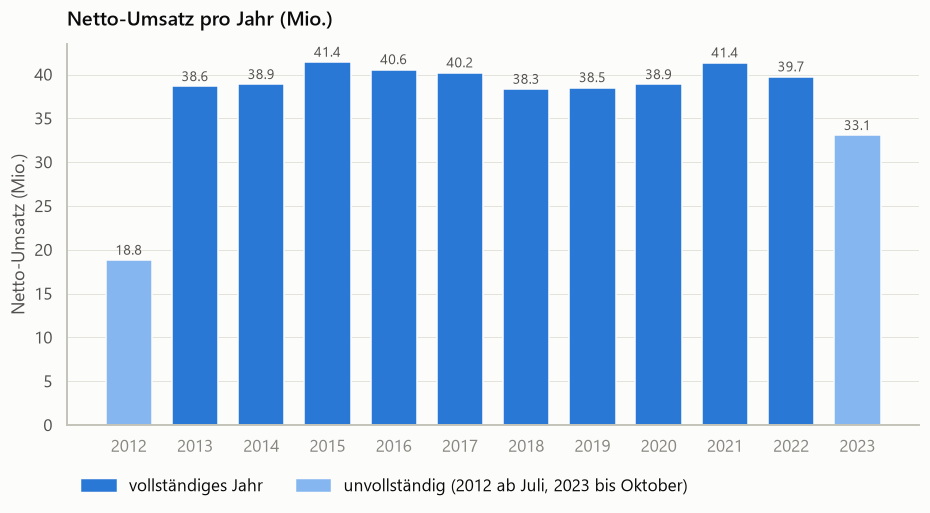

In [2]:
df1 = sql_laden("01_umsatzentwicklung.sql")
display(df1)

fig, ax = plt.subplots(figsize=(10, 4.5))
voll = df1["Monate"] == 12
ax.bar(df1["Jahr"], df1["Netto_Umsatz"] / 1e6, width=0.7,
       color=[BLAU if v else BLAU_HELL for v in voll], edgecolor=FLAECHE, linewidth=1)
for x, y in zip(df1["Jahr"], df1["Netto_Umsatz"] / 1e6):
    ax.text(x, y + 0.6, f"{y:.1f}", ha="center", fontsize=9, color=TEXT2)
ax.set_title("Netto-Umsatz pro Jahr (Mio.)")
ax.set_ylabel("Netto-Umsatz (Mio.)")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=BLAU, label="vollständiges Jahr"),
                   Patch(color=BLAU_HELL, label="unvollständig (2012 ab Juli, 2023 bis Oktober)")],
          loc="upper left", bbox_to_anchor=(0, -0.1), ncol=2)
speichern(fig, "01_umsatzentwicklung.png")
plt.show()

**Erkenntnis:** Der Umsatz stagniert. In allen vollständigen Jahren (2013–2022) liegt er zwischen
38,3 und 41,4 Mio. – über zehn Jahre insgesamt nur **+2,9 %**. Die Veränderungen von Jahr zu Jahr bewegen
sich zwischen −4,7 % und +6,6 %. 2023 liegt nach zehn Monaten bei 33,1 Mio. und damit 1,9 % über
Januar–Oktober 2022; hochgerechnet ist das wieder ein normales Jahr mit rund 40 Mio.

## 2. Welche Produkte tragen den Umsatz? (ABC-Analyse)

,Rang,Produkt,Kategorie,Netto_Umsatz,Anteil_Pct,Kum_Anteil_Pct,ABC_Klasse
0,1,Côte de Blaye,Beverages,"53,265,895.00",11.88,11.90,A
1,2,Thüringer Rostbratwurst,Meat/Poultry,"24,623,469.00",5.49,17.40,A
2,3,Mishi Kobe Niku,Meat/Poultry,"19,423,038.00",4.33,21.70,A
3,4,Sir Rodney's Marmalade,Confections,"16,653,807.00",3.71,25.40,A
4,5,Carnarvon Tigers,Seafood,"12,604,672.00",2.81,28.20,A
5,6,Raclette Courdavault,Dairy Products,"11,216,411.00",2.50,30.70,A
6,7,Manjimup Dried Apples,Produce,"10,664,769.00",2.38,33.10,A
7,8,Tarte au sucre,Confections,"9,952,936.00",2.22,35.30,A
8,9,Ipoh Coffee,Beverages,"9,333,375.00",2.08,37.40,A
9,10,Rössle Sauerkraut,Produce,"9,252,765.00",2.06,39.50,A


Gespeichert: images/02_abc_analyse_produkte.png


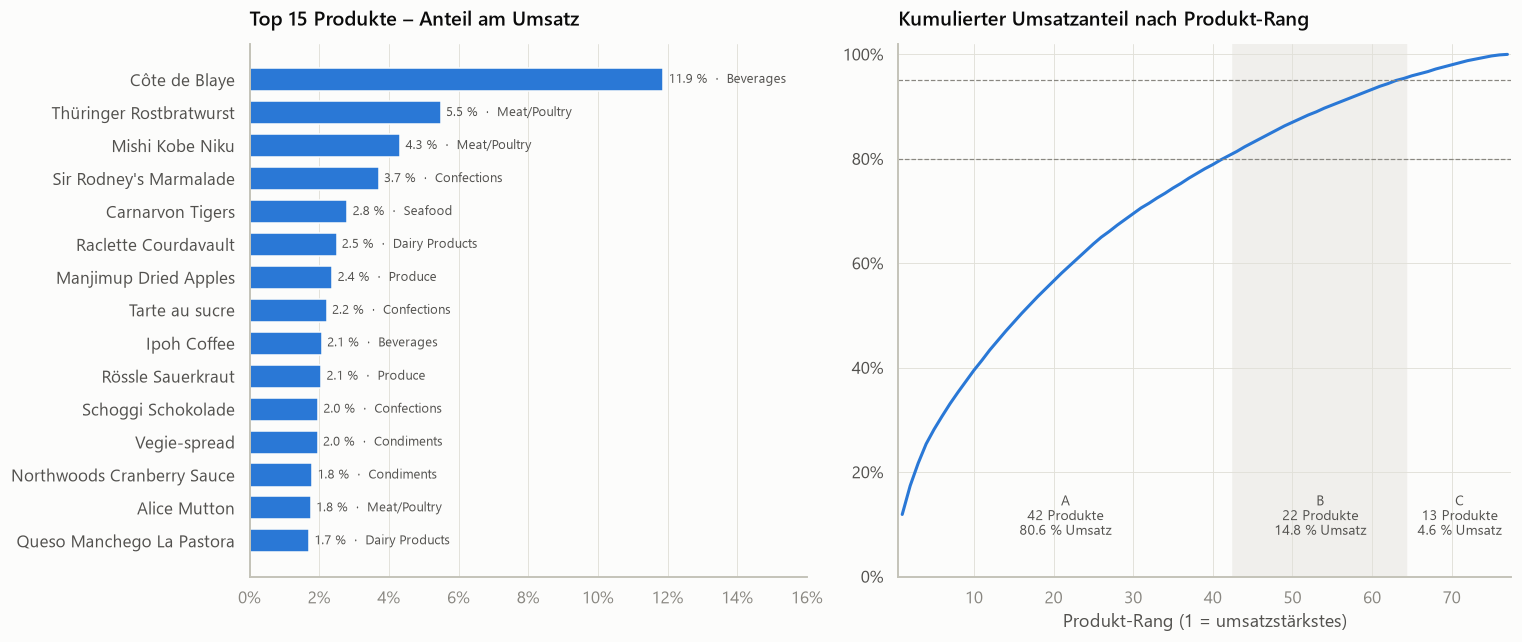

In [3]:
df2 = sql_laden("02_abc_analyse_produkte.sql")
display(df2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.1]})

# Links: Top 15 Produkte nach Umsatzanteil
top = df2.head(15).iloc[::-1]
ax1.barh(top["Produkt"], top["Anteil_Pct"], color=BLAU, height=0.7, edgecolor=FLAECHE, linewidth=1)
for y, (v, k) in enumerate(zip(top["Anteil_Pct"], top["Kategorie"])):
    ax1.text(v + 0.15, y, f"{v:.1f} %  ·  {k}", va="center", fontsize=8.5, color=TEXT2)
ax1.set_title("Top 15 Produkte – Anteil am Umsatz")
ax1.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax1.set_xlim(0, 16)
ax1.grid(axis="y", visible=False)

# Rechts: kumulierter Umsatzanteil über alle Produkte
ax2.plot(df2["Rang"], df2["Kum_Anteil_Pct"], color=BLAU, linewidth=2)
grenzen = df2.groupby("ABC_Klasse")["Rang"].agg(["min", "max"])
for klasse, (von, bis) in grenzen.iterrows():
    ax2.axvspan(von - 0.5, bis + 0.5, color="#f0efec" if klasse == "B" else FLAECHE, zorder=0)
    n = bis - von + 1
    anteil = df2.loc[df2["ABC_Klasse"] == klasse, "Anteil_Pct"].sum()
    ax2.text((von + bis) / 2, 8, f"{klasse}\n{n} Produkte\n{anteil:.1f} % Umsatz",
             ha="center", fontsize=9, color=TEXT2)
for h in (80, 95):
    ax2.axhline(h, color=GEDAEMPFT, linewidth=0.8, linestyle="--")
ax2.set_title("Kumulierter Umsatzanteil nach Produkt-Rang")
ax2.set_xlabel("Produkt-Rang (1 = umsatzstärkstes)")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.set_ylim(0, 102)
ax2.set_xlim(0.5, len(df2) + 0.5)

fig.tight_layout()
speichern(fig, "02_abc_analyse_produkte.png")
plt.show()

**Erkenntnis:** Ein Produkt sticht heraus: **Côte de Blaye** bringt allein **11,9 %** des Umsatzes – mehr
als doppelt so viel wie Platz 2 (Thüringer Rostbratwurst, 5,5 %). Danach ist der Umsatz breit verteilt:
Für 80 % des Umsatzes braucht es **42 der 77 Produkte**. Die klassische 80/20-Regel gilt hier also nicht.
Die stärkste Kategorie ist Beverages (20,6 %), vor allem wegen Côte de Blaye. Die 13 C-Produkte
(zusammen 4,6 %) sind Kandidaten für eine Sortimentsprüfung.

## 3. Wie entwickeln sich die Verkaufspreise im Vergleich zum Listenpreis?

,Jahr,Stueck,Avg_Verkaufspreis,Avg_Listenpreis,Preisindex_Pct,Unter_Listenpreis_Pct,Avg_Rabatt_Pct
0,2012,655344,28.72,28.72,100.00,0.00,0.00
1,2013,1346377,28.69,28.69,100.00,0.00,0.00
2,2014,1352623,28.74,28.74,100.00,0.00,0.00
3,2015,1437596,28.81,28.81,100.00,0.00,0.00
4,2016,1405527,28.88,28.92,99.90,0.70,0.05
5,2017,1400274,28.75,28.77,99.90,0.50,0.12
6,2018,1328021,28.88,28.88,100.00,0.00,0.08
7,2019,1324934,29.07,29.07,100.00,0.00,0.00
8,2020,1340375,28.99,28.99,100.00,0.00,0.00
9,2021,1431155,28.90,28.90,100.00,0.00,0.00


Gespeichert: images/03_preisentwicklung.png


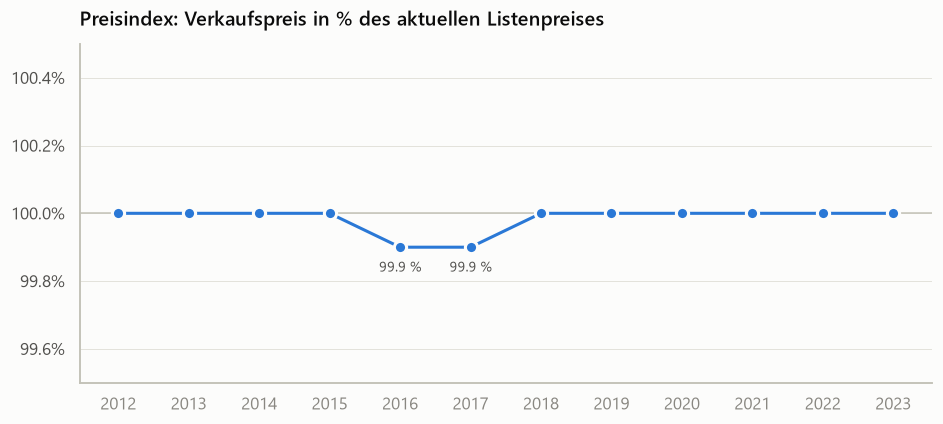

In [4]:
df3 = sql_laden("03_preisentwicklung.sql")
display(df3)

fig, ax = plt.subplots(figsize=(10, 4))
ax.axhline(100, color=ACHSE, linewidth=1)
ax.plot(df3["Jahr"], df3["Preisindex_Pct"], color=BLAU, linewidth=2, marker="o", markersize=8,
        markeredgecolor=FLAECHE, markeredgewidth=2)
for x, y in zip(df3["Jahr"], df3["Preisindex_Pct"]):
    if y < 100:
        ax.annotate(f"{y:.1f} %", (x, y), xytext=(0, -16), textcoords="offset points",
                    ha="center", fontsize=9, color=TEXT2)
ax.set_title("Preisindex: Verkaufspreis in % des aktuellen Listenpreises")
ax.set_ylim(99.5, 100.5)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.grid(axis="x", visible=False)
speichern(fig, "03_preisentwicklung.png")
plt.show()

**Erkenntnis:** Verkauft wird praktisch immer zum heutigen Listenpreis (Preisindex 99,9–100 %, Achse
bewusst stark gezoomt). In zwölf Jahren gab es weder Preiserhöhungen noch spürbare Preisnachlässe.
In echten Daten wäre das unrealistisch (Inflation). Es deutet darauf hin, dass die synthetischen
Bestellungen mit den aktuellen Listenpreisen erzeugt wurden. Die minimalen Abweichungen 2016–2017 fallen
in denselben Zeitraum wie die Rabatte (Frage 10). **Preispolitik ist mit diesen Daten nicht analysierbar.**

## 4. Wer sind die Top-10-Kunden, und wie hoch ist das Klumpenrisiko?

,Rang,Kunde,Land,Bestellungen,Netto_Umsatz,Anteil_Pct,Kum_Anteil_Pct,Gleichverteilung_Pct
0,1,B's Beverages,UK,210,"6,154,115.00",1.37,1.40,1.10
1,2,Hungry Coyote Import Store,USA,198,"5,698,024.00",1.27,2.60,2.20
2,3,Rancho grande,Argentina,194,"5,559,110.00",1.24,3.90,3.20
3,4,Gourmet Lanchonetes,Brazil,202,"5,552,310.00",1.24,5.10,4.30
4,5,Ana Trujillo Emparedados y helados,Mexico,195,"5,534,357.00",1.23,6.40,5.40
5,6,Ricardo Adocicados,Brazil,203,"5,524,517.00",1.23,7.60,6.50
6,7,Folies gourmandes,France,195,"5,505,503.00",1.23,8.80,7.50
7,8,Let's Stop N Shop,USA,191,"5,462,198.00",1.22,10.00,8.60
8,9,LILA-Supermercado,Venezuela,203,"5,437,438.00",1.21,11.20,9.70
9,10,Princesa Isabel Vinhos,Portugal,200,"5,436,771.00",1.21,12.50,10.80


Gespeichert: images/04_top_kunden.png


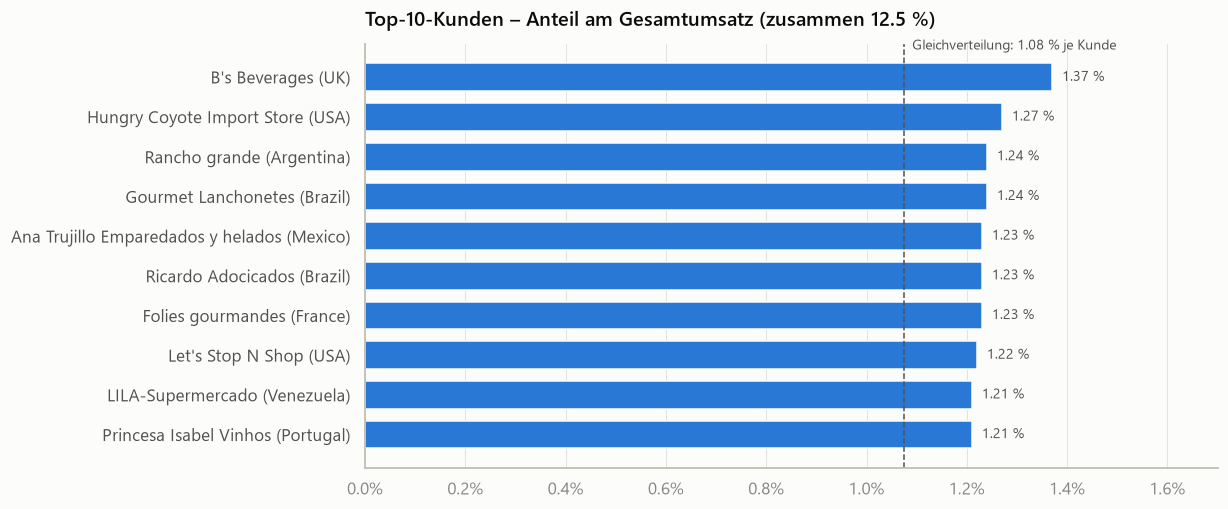

In [5]:
df4 = sql_laden("04_top_kunden_klumpenrisiko.sql")
display(df4)
anzahl_kunden = pd.read_sql_query("SELECT COUNT(DISTINCT CustomerID) AS n FROM Orders", con)["n"][0]
gleich = 100 / anzahl_kunden

fig, ax = plt.subplots(figsize=(10, 5))
d = df4.iloc[::-1]
labels = [f"{k} ({l})" for k, l in zip(d["Kunde"], d["Land"])]
ax.barh(labels, d["Anteil_Pct"], color=BLAU, height=0.7, edgecolor=FLAECHE, linewidth=1)
for y, v in enumerate(d["Anteil_Pct"]):
    ax.text(v + 0.02, y, f"{v:.2f} %", va="center", fontsize=9, color=TEXT2)
ax.axvline(gleich, color=TEXT2, linewidth=1, linestyle="--")
ax.text(gleich, len(d) - 0.3, f"  Gleichverteilung: {gleich:.2f} % je Kunde", fontsize=9, color=TEXT2)
ax.set_title(f"Top-10-Kunden – Anteil am Gesamtumsatz (zusammen {df4['Kum_Anteil_Pct'].iloc[-1]:.1f} %)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.set_xlim(0, 1.7)
ax.grid(axis="y", visible=False)
speichern(fig, "04_top_kunden.png")
plt.show()

**Erkenntnis:** Es gibt **kein Klumpenrisiko**. Die Top-10-Kunden bringen zusammen nur **12,5 %** des
Umsatzes, der größte Kunde (B's Beverages, UK) 1,4 %. Bei Gleichverteilung hätte jeder der 93 Kunden
1,1 % – selbst die besten Kunden liegen kaum darüber. Der Verlust eines einzelnen Kunden wäre gut
verkraftbar.

## 5. Welche Kunden kaufen weniger als im Vorjahr? (Churn)

,Kunde,Land,Letzte_Bestellung,Umsatz_Vorjahr_12M,Umsatz_Letzte_12M,Veraenderung_Pct,Status
0,Princesa Isabel Vinhos,Portugal,2023-10-23,"637,947.00","196,184.00",-69.20,Stark rückläufig (> -30 %)
1,Pericles Comidas clásicas,Mexico,2023-07-27,"539,425.00","186,468.00",-65.40,Stark rückläufig (> -30 %)
2,Toms Spezialitäten,Germany,2023-10-09,"625,686.00","260,728.00",-58.30,Stark rückläufig (> -30 %)
3,Mère Paillarde,Canada,2023-07-09,"408,565.00","174,339.00",-57.30,Stark rückläufig (> -30 %)
4,Island Trading,UK,2023-09-28,"488,414.00","214,302.00",-56.10,Stark rückläufig (> -30 %)
5,Wilman Kala,Finland,2023-10-24,"636,000.00","279,848.00",-56.00,Stark rückläufig (> -30 %)
6,Consolidated Holdings,UK,2023-10-20,"892,846.00","418,284.00",-53.20,Stark rückläufig (> -30 %)
7,B's Beverages,UK,2023-10-18,"878,255.00","466,354.00",-46.90,Stark rückläufig (> -30 %)
8,Great Lakes Food Market,USA,2023-10-22,"488,307.00","284,066.00",-41.80,Stark rückläufig (> -30 %)
9,Océano Atlántico Ltda.,Argentina,2023-10-19,"527,990.00","308,971.00",-41.50,Stark rückläufig (> -30 %)


Gespeichert: images/05_kundenabwanderung.png


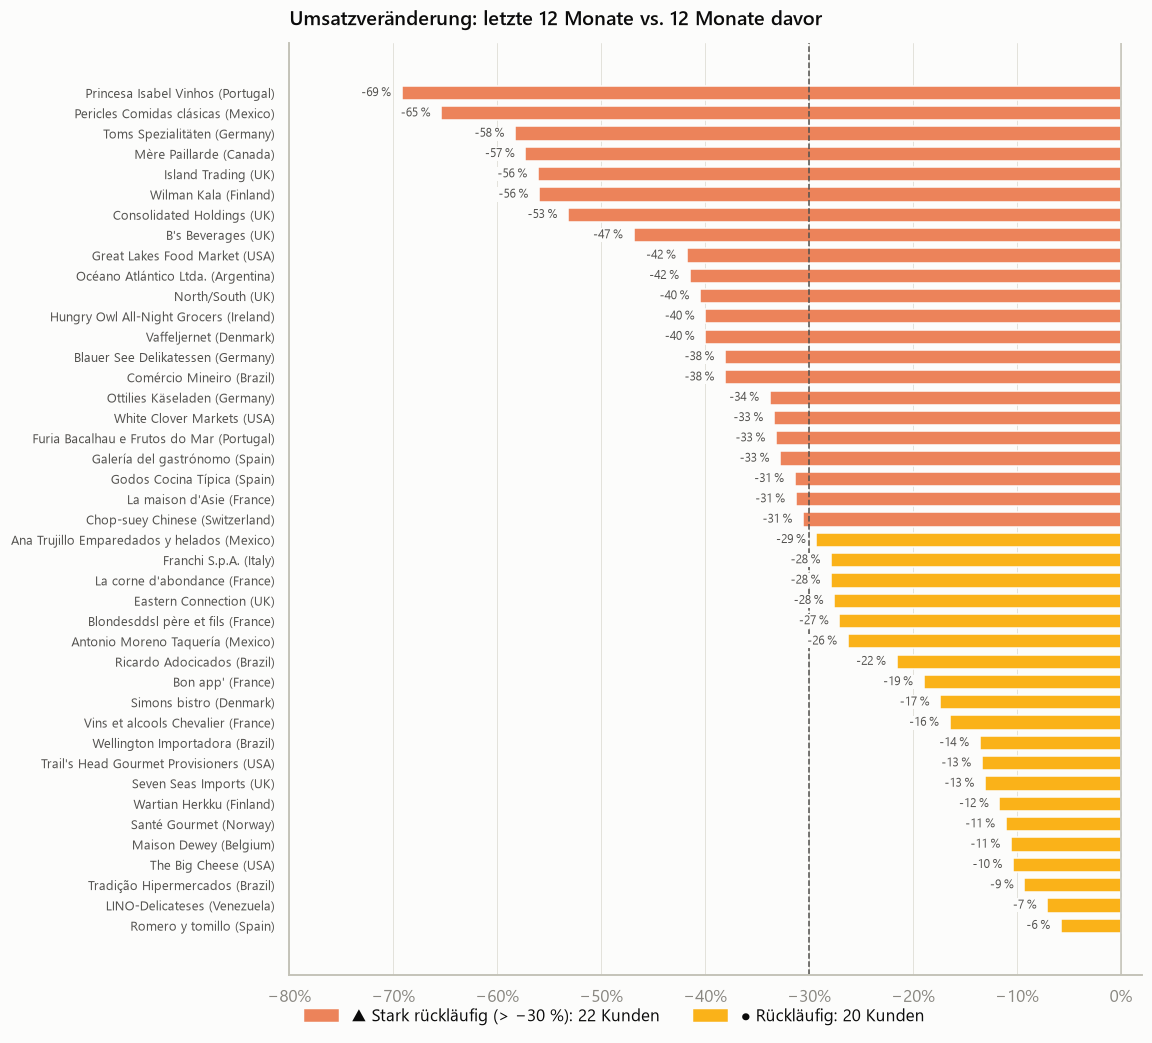

In [6]:
df5 = sql_laden("05_kundenabwanderung.sql")
display(df5)

stark = df5["Status"].str.startswith("Stark")
fig, ax = plt.subplots(figsize=(10, 11))
d = df5.iloc[::-1]
ax.barh(d["Kunde"] + " (" + d["Land"] + ")", d["Veraenderung_Pct"], height=0.7,
        color=[STATUS_ERNST if s else STATUS_WARNUNG for s in stark[::-1]],
        edgecolor=FLAECHE, linewidth=1)
for y, v in enumerate(d["Veraenderung_Pct"]):
    ax.text(v - 1, y, f"{v:.0f} %", va="center", ha="right", fontsize=8, color=TEXT2,
            bbox=dict(boxstyle="square,pad=0.1", fc=FLAECHE, ec="none"), zorder=4)
ax.axvline(-30, color=TEXT2, linewidth=1, linestyle="--", zorder=1)
ax.axvline(0, color=ACHSE, linewidth=1)
ax.set_title("Umsatzveränderung: letzte 12 Monate vs. 12 Monate davor")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(-80, 2)
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=STATUS_ERNST, label=f"▲ Stark rückläufig (> −30 %): {stark.sum()} Kunden"),
                   Patch(color=STATUS_WARNUNG, label=f"● Rückläufig: {(~stark).sum()} Kunden")],
          loc="lower left", bbox_to_anchor=(0, -0.07), ncol=2)
speichern(fig, "05_kundenabwanderung.png")
plt.show()

**Erkenntnis:** **42 von 93 Kunden** haben in den letzten 12 Monaten (bis 28.10.2023) weniger gekauft als
in den 12 Monaten davor, **22 davon mehr als 30 % weniger**. Am stärksten betroffen sind Princesa Isabel
Vinhos (−69 %), Pericles Comidas clásicas (−65 %) und Toms Spezialitäten (−58 %). Komplett verloren ist
noch kein Kunde, aber Pericles und Mère Paillarde haben seit Juli 2023 nicht mehr bestellt. Die 22 stark
rückläufigen Kunden sind die erste Zielgruppe für Gespräche durch den Vertrieb.

## 6. Welche Länder wachsen, welche schrumpfen?

,Land,Kunden,Umsatz_Gesamt,Anteil_Pct,Umsatz_pro_Kunde,Umsatz_2013,Umsatz_2022,Veraenderung_Pct
0,Finland,2,"9,210,007.00",2.10,"4,605,003.00","592,602.00","1,248,976.00",110.80
1,Poland,1,"4,738,465.00",1.10,"4,738,465.00","265,589.00","420,699.00",58.40
2,Switzerland,2,"9,823,389.00",2.20,"4,911,694.00","714,378.00","988,190.00",38.30
3,France,11,"53,323,306.00",11.90,"4,847,573.00","3,938,537.00","5,421,994.00",37.70
4,Argentina,3,"14,233,567.00",3.20,"4,744,522.00","1,077,500.00","1,336,409.00",24.00
5,Spain,5,"24,023,498.00",5.40,"4,804,700.00","1,937,699.00","2,292,375.00",18.30
6,Germany,11,"51,195,767.00",11.40,"4,654,161.00","3,817,728.00","4,492,389.00",17.70
7,Austria,2,"9,908,284.00",2.20,"4,954,142.00","930,760.00","1,059,769.00",13.90
8,(unbekannt),2,"9,745,371.00",2.20,"4,872,686.00","933,471.00","1,033,706.00",10.70
9,UK,7,"33,959,255.00",7.60,"4,851,322.00","3,059,031.00","3,308,903.00",8.20


Gespeichert: images/06_laender_wachstum.png


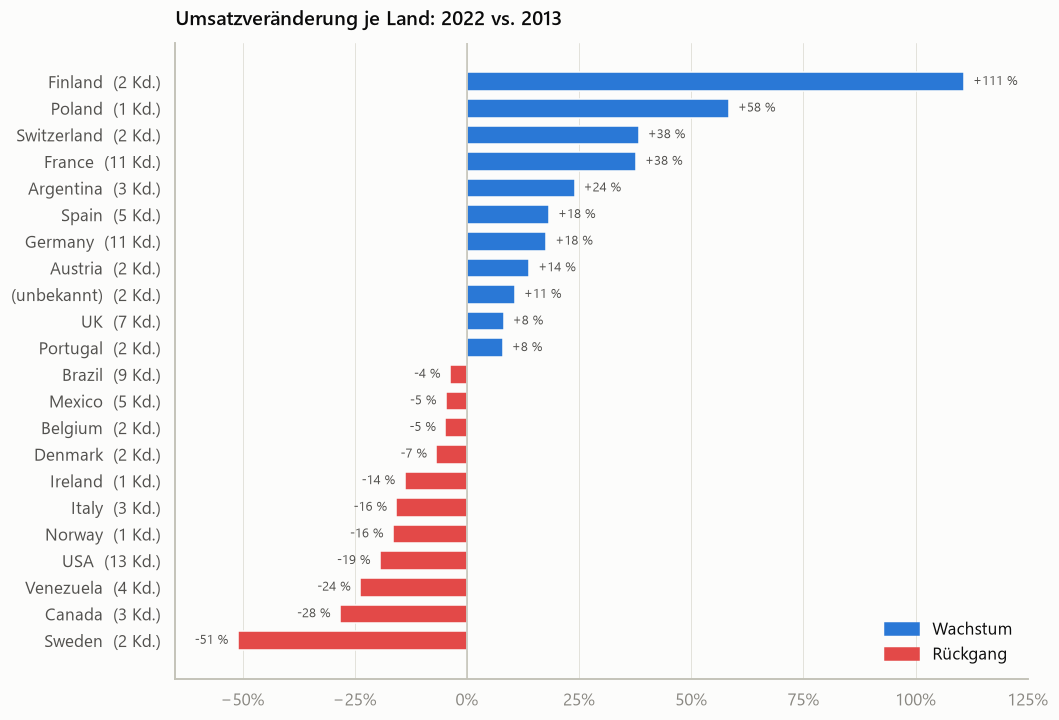

In [7]:
df6 = sql_laden("06_laender_wachstum.sql")
display(df6)

fig, ax = plt.subplots(figsize=(10, 7.5))
d = df6.sort_values("Veraenderung_Pct")
labels = [f"{l}  ({k} Kd.)" for l, k in zip(d["Land"], d["Kunden"])]
ax.barh(labels, d["Veraenderung_Pct"], height=0.7, edgecolor=FLAECHE, linewidth=1,
        color=[BLAU if v >= 0 else ROT for v in d["Veraenderung_Pct"]])
for y, v in enumerate(d["Veraenderung_Pct"]):
    ax.text(v + (2 if v >= 0 else -2), y, f"{v:+.0f} %", va="center",
            ha="left" if v >= 0 else "right", fontsize=8.5, color=TEXT2)
ax.axvline(0, color=ACHSE, linewidth=1)
ax.set_title("Umsatzveränderung je Land: 2022 vs. 2013")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_xlim(-65, 125)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=BLAU, label="Wachstum"), Patch(color=ROT, label="Rückgang")],
          loc="lower right")
speichern(fig, "06_laender_wachstum.png")
plt.show()

**Erkenntnis:** **Europa wächst, Amerika schrumpft.** Frankreich (+38 %) und Deutschland (+18 %) – zusammen
23 % des Umsatzes – legen deutlich zu; Finnland verdoppelt sich sogar (+111 %). Der größte Markt, die **USA**
(14 % Umsatzanteil), verliert dagegen **19 %**, ebenso Kanada (−28 %) und Venezuela (−24 %); Schweden halbiert
sich (−51 %). Vorsicht bei Ländern mit nur 1–2 Kunden: Dort kann ein einzelner Kunde das Ergebnis bestimmen.
„(unbekannt)“ sind die zwei vermutlichen Testkunden Val2/VALON.

## 7. Wie pünktlich wird geliefert – je Versender, Mitarbeiter und Zielland?

,Dimension,Wert,Lieferungen,Verspaetet,Verspaetet_Pct,Avg_Durchlaufzeit_Tage,Avg_Tage_zu_spaet
0,Versender,Speedy Express,5331,1244,23.30,7.90,6.90
1,Versender,Federal Shipping,5455,1255,23.00,7.80,7.00
2,Versender,United Package,5475,1256,22.90,7.80,7.00
3,Mitarbeiter,Robert King,1786,435,24.40,8.00,7.30
4,Mitarbeiter,Anne Dodsworth,1765,429,24.30,7.90,6.60
5,Mitarbeiter,Laura Callahan,1794,430,24.00,7.90,6.90
6,Mitarbeiter,Janet Leverling,1846,439,23.80,7.80,6.90
7,Mitarbeiter,Michael Suyama,1752,416,23.70,8.00,7.00
8,Mitarbeiter,Steven Buchanan,1804,399,22.10,7.60,7.10
9,Mitarbeiter,Margaret Peacock,1903,420,22.10,8.00,7.20


Gespeichert: images/07_liefertreue.png


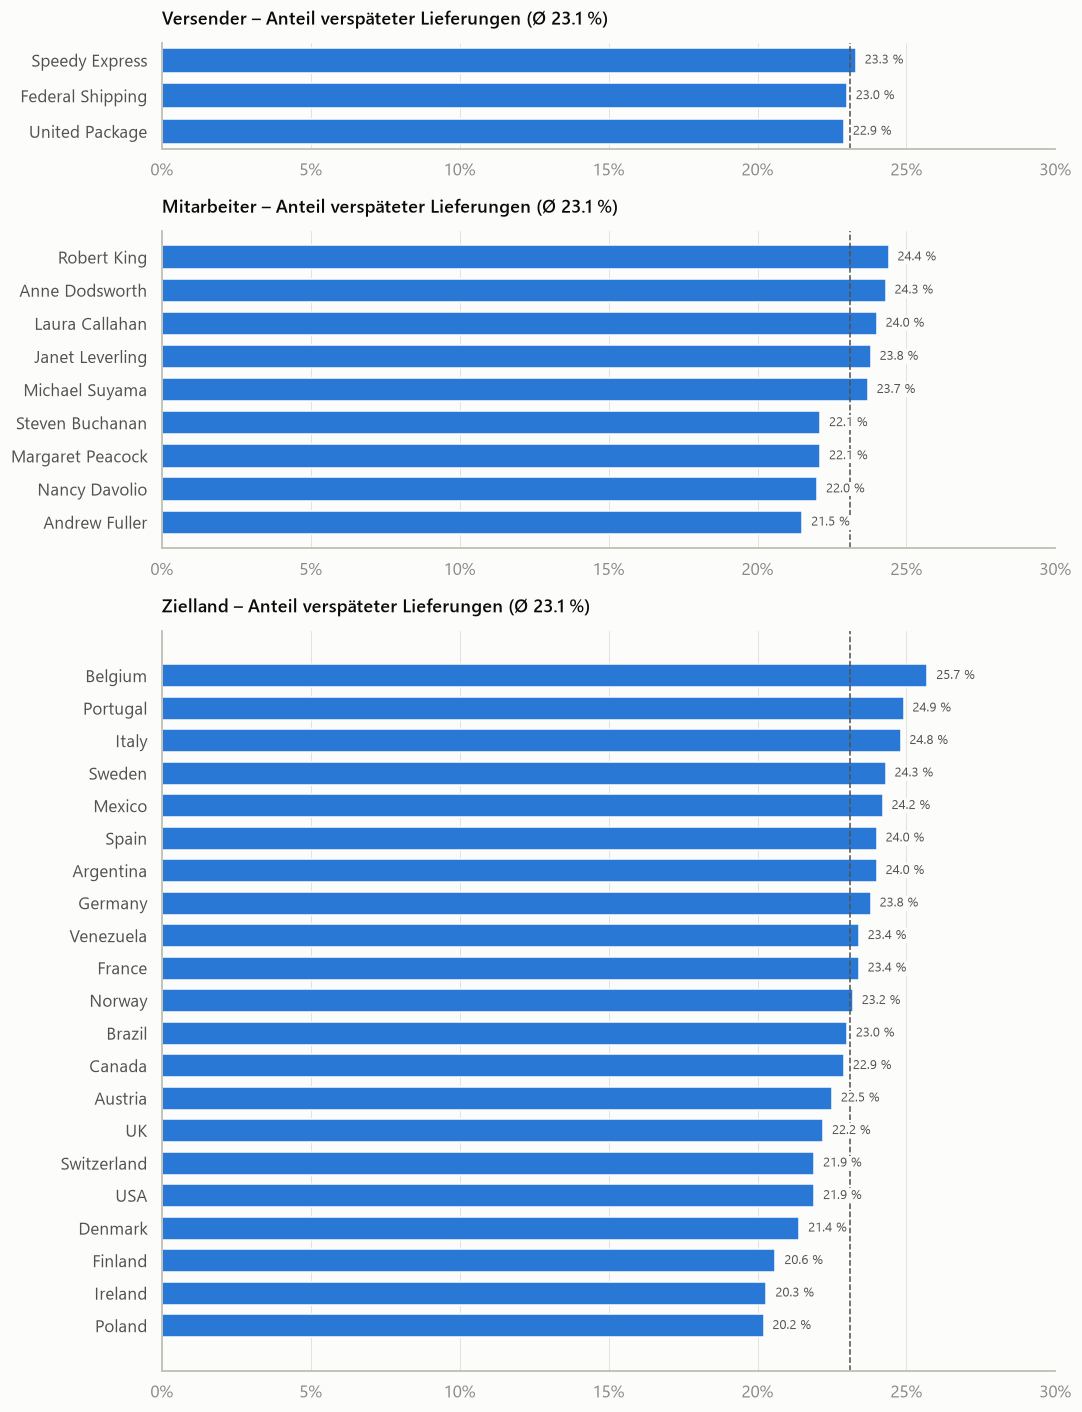

In [8]:
df7 = sql_laden("07_liefertreue.sql")
display(df7)

dims = ["Versender", "Mitarbeiter", "Zielland"]
groessen = [(df7["Dimension"] == d).sum() for d in dims]
fig, axes = plt.subplots(3, 1, figsize=(10, 13), gridspec_kw={"height_ratios": groessen})
for ax, dim in zip(axes, dims):
    d = df7[df7["Dimension"] == dim].sort_values("Verspaetet_Pct")
    schnitt = 100 * d["Verspaetet"].sum() / d["Lieferungen"].sum()
    ax.barh(d["Wert"], d["Verspaetet_Pct"], color=BLAU, height=0.7, edgecolor=FLAECHE, linewidth=1)
    for y, v in enumerate(d["Verspaetet_Pct"]):
        ax.text(v + 0.3, y, f"{v:.1f} %", va="center", fontsize=8.5, color=TEXT2,
                bbox=dict(boxstyle="square,pad=0.1", fc=FLAECHE, ec="none"), zorder=4)
    ax.axvline(schnitt, color=TEXT2, linewidth=1, linestyle="--", zorder=1)
    ax.set_title(f"{dim} – Anteil verspäteter Lieferungen (Ø {schnitt:.1f} %)", fontsize=11.5)
    ax.set_xlim(0, 30)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
speichern(fig, "07_liefertreue.png")
plt.show()

**Erkenntnis:** Rund **23 % aller Lieferungen** werden nach dem gewünschten Liefertermin versendet,
im Schnitt etwa **7 Tage zu spät**. Das ist das größte operative Problem in den Daten. Die Quote ist aber
überall fast gleich: Versender 22,9–23,3 %, Mitarbeiter 21,5–24,4 %, Zielländer 20,2–25,7 %. Es gibt also
**keinen einzelnen Verursacher**; die Ursache liegt eher im Prozess, z. B. bei zu knapp gesetzten
Lieferterminen. (Die Gleichmäßigkeit ist auch eine Folge der synthetischen Daten.)

## 8. Wie hoch sind die Frachtkosten im Verhältnis zum Warenwert?

,Dimension,Wert,Bestellungen,Fracht_Gesamt,Avg_Fracht,Avg_Warenwert,Frachtquote_Pct
0,Versender,United Package,5486,"1,358,547.00",247.64,"27,371.00",0.91
1,Versender,Federal Shipping,5461,"1,358,039.00",248.68,"27,515.00",0.90
2,Versender,Speedy Express,5335,"1,330,885.00",249.46,"27,735.00",0.90
3,Zielland,Sweden,391,"95,648.00",244.62,"26,702.00",0.92
4,Zielland,Italy,538,"131,315.00",244.08,"26,846.00",0.91
5,Zielland,Germany,2193,"537,190.00",244.96,"26,947.00",0.91
6,Zielland,Finland,369,"89,242.00",241.85,"26,604.00",0.91
7,Zielland,Austria,380,"93,234.00",245.35,"26,990.00",0.91
8,Zielland,Portugal,357,"91,889.00",257.39,"28,352.00",0.91
9,Zielland,Brazil,1683,"418,465.00",248.64,"27,481.00",0.91


Gespeichert: images/08_frachtkosten.png


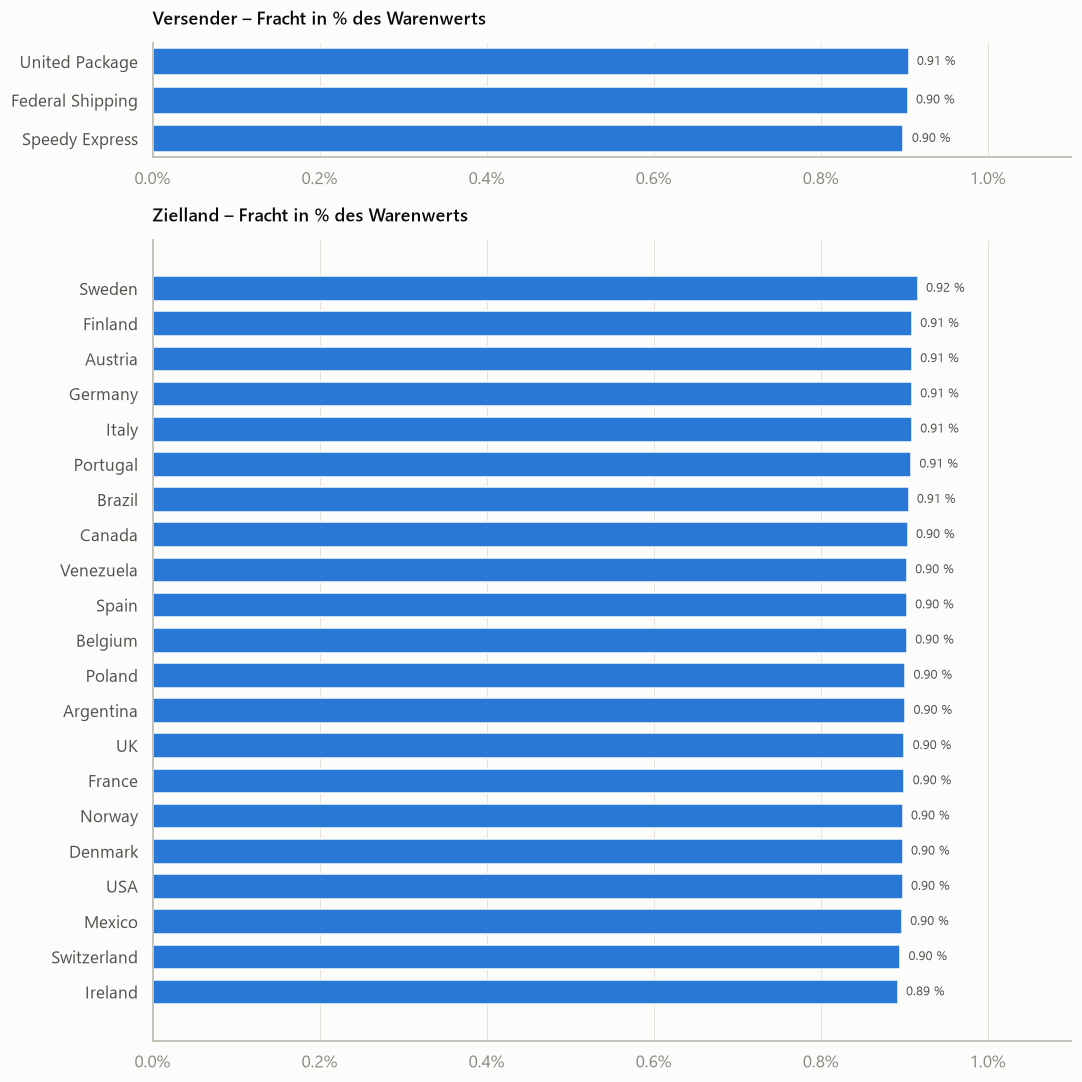

In [9]:
df8 = sql_laden("08_frachtkosten.sql")
display(df8)

dims = ["Versender", "Zielland"]
groessen = [(df8["Dimension"] == d).sum() for d in dims]
fig, axes = plt.subplots(2, 1, figsize=(10, 10), gridspec_kw={"height_ratios": groessen})
for ax, dim in zip(axes, dims):
    d = df8[df8["Dimension"] == dim].sort_values("Frachtquote_Pct")
    ax.barh(d["Wert"], d["Frachtquote_Pct"], color=BLAU, height=0.7, edgecolor=FLAECHE, linewidth=1)
    for y, v in enumerate(d["Frachtquote_Pct"]):
        ax.text(v + 0.01, y, f"{v:.2f} %", va="center", fontsize=8.5, color=TEXT2)
    ax.set_title(f"{dim} – Fracht in % des Warenwerts", fontsize=11.5)
    ax.set_xlim(0, 1.1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
speichern(fig, "08_frachtkosten.png")
plt.show()

**Erkenntnis:** Die Fracht kostet überall rund **0,9 % des Warenwerts** (0,89–0,92 %), unabhängig von
Versender und Zielland – im Schnitt ca. 249 Fracht bei ca. 27.500 Warenwert pro Bestellung. Kein
Versender ist teurer als die anderen, und auch Fernziele sind nicht teurer. **Frachtkosten sind kein
Hebel für die Marge.**

## 9. Welche Mitarbeiter erzielen den meisten Umsatz, und wie entwickeln sie sich?

,Mitarbeiter,Titel,Region,Bestellungen,Netto_Umsatz,Anteil_Pct,Avg_Bestellwert,Umsatz_2013,Umsatz_2022,Veraenderung_Pct
0,Margaret Peacock,Sales Representative,Eastern,1908,"51,488,395.00",11.50,"26,986.00","4,215,115.00","4,420,627.00",4.90
1,Steven Buchanan,Sales Manager,Eastern,1804,"51,386,459.00",11.50,"28,485.00","4,572,265.00","4,671,595.00",2.20
2,Janet Leverling,Sales Representative,Southern,1846,"50,445,574.00",11.30,"27,327.00","4,278,745.00","3,844,719.00",-10.10
3,Nancy Davolio,Sales Representative,Eastern,1846,"49,659,423.00",11.10,"26,901.00","5,472,860.00","4,300,391.00",-21.40
4,Robert King,Sales Representative,Western,1789,"49,651,899.00",11.10,"27,754.00","3,694,951.00","5,031,166.00",36.20
5,Laura Callahan,Inside Sales Coordinator,Northern,1798,"49,281,137.00",11.00,"27,409.00","3,939,368.00","3,926,407.00",-0.30
6,Michael Suyama,Sales Representative,Western,1754,"49,139,967.00",11.00,"28,016.00","4,129,205.00","4,344,931.00",5.20
7,Anne Dodsworth,Sales Representative,Northern,1766,"49,019,678.00",10.90,"27,757.00","4,264,054.00","4,664,363.00",9.40
8,Andrew Fuller,"Vice President, Sales",Eastern,1771,"48,314,101.00",10.80,"27,281.00","4,066,558.00","4,537,867.00",11.60


Gespeichert: images/09_mitarbeiter_performance.png


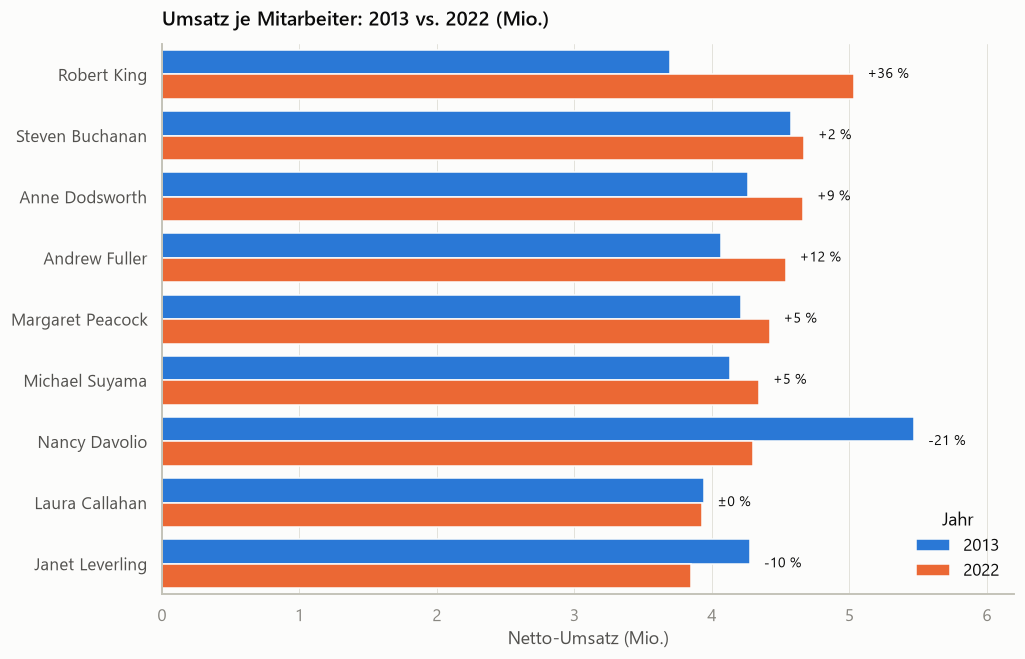

In [10]:
df9 = sql_laden("09_mitarbeiter_performance.sql")
display(df9)

lang = df9.melt(id_vars=["Mitarbeiter", "Veraenderung_Pct"],
                value_vars=["Umsatz_2013", "Umsatz_2022"], var_name="Jahr", value_name="Umsatz")
lang["Jahr"] = lang["Jahr"].str[-4:]
lang["Umsatz_Mio"] = lang["Umsatz"] / 1e6
reihenfolge = df9.sort_values("Umsatz_2022", ascending=False)["Mitarbeiter"].tolist()

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.barplot(data=lang, y="Mitarbeiter", x="Umsatz_Mio", hue="Jahr", order=reihenfolge,
            palette=[BLAU, ORANGE], saturation=1, orient="h", ax=ax, edgecolor=FLAECHE, linewidth=1)
for y, name in enumerate(reihenfolge):
    zeile = df9[df9["Mitarbeiter"] == name].iloc[0]
    v = zeile["Veraenderung_Pct"]
    ax.text(max(zeile["Umsatz_2013"], zeile["Umsatz_2022"]) / 1e6 + 0.1, y,
            "±0 %" if abs(v) < 0.5 else f"{v:+.0f} %", va="center", fontsize=9, color=TEXT)
ax.set_title("Umsatz je Mitarbeiter: 2013 vs. 2022 (Mio.)")
ax.set_xlabel("Netto-Umsatz (Mio.)")
ax.set_ylabel("")
ax.set_xlim(0, 6.2)
ax.grid(axis="y", visible=False)
ax.legend(title="Jahr", loc="lower right")
speichern(fig, "09_mitarbeiter_performance.png")
plt.show()

**Erkenntnis:** Über den gesamten Zeitraum liegen alle 9 Mitarbeiter eng beieinander (10,8–11,5 %
Umsatzanteil). Spannend ist die Entwicklung: **Robert King** hat seinen Umsatz von 2013 auf 2022 um
**+36 %** gesteigert und ist 2022 der stärkste Verkäufer. **Nancy Davolio (−21 %)** und Janet Leverling
(−10 %) verlieren dagegen deutlich – 2013 war Davolio noch die Nummer 1. Auffällig: Andrew Fuller
(Vice President) und Steven Buchanan (Sales Manager) verkaufen selbst ebenso viel wie die Sales
Representatives.

## 10. Steigern Rabatte die Bestellmenge?

,Rabatt_Pct,Positionen,Avg_Menge_pro_Position,Avg_Stueckpreis,Brutto_Umsatz,Rabatt_Betrag,Netto_Umsatz
0,0,99148,25.40,28.77,"72,590,727.00",0.00,"72,590,727.00"
1,1,1,2.00,15.00,30.00,0.00,30.00
2,2,2,2.00,18.50,61.00,1.00,60.00
3,3,3,1.70,24.65,125.00,4.00,121.00
4,4,1,1.00,81.00,81.00,3.00,78.00
5,5,185,28.00,30.80,"155,387.00","7,769.00","147,617.00"
6,6,1,2.00,34.00,68.00,4.00,64.00
7,10,173,25.20,25.17,"101,666.00","10,167.00","91,499.00"
8,15,157,28.40,22.98,"102,948.00","15,442.00","87,506.00"
9,20,161,27.00,23.53,"111,476.00","22,295.00","89,181.00"


Gespeichert: images/10_rabattwirkung.png


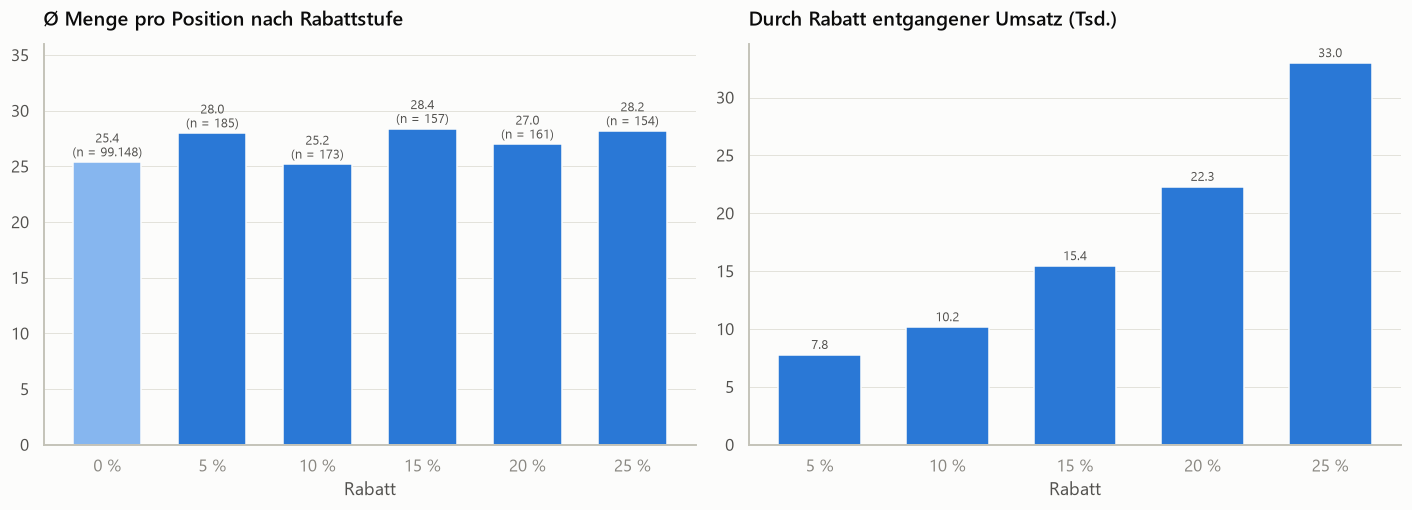

In [11]:
df10 = sql_laden("10_rabattwirkung.sql")
display(df10)

# Nur Rabattstufen mit genügend Positionen (die Stufen 1–6 % außer 5 % kommen nur 1–3 Mal vor)
d = df10[df10["Positionen"] >= 100].copy()
d["Stufe"] = d["Rabatt_Pct"].astype(str) + " %"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
ax1.bar(d["Stufe"], d["Avg_Menge_pro_Position"], width=0.65, edgecolor=FLAECHE, linewidth=1,
        color=[BLAU_HELL if r == 0 else BLAU for r in d["Rabatt_Pct"]])
for x, (v, n) in enumerate(zip(d["Avg_Menge_pro_Position"], d["Positionen"])):
    ax1.text(x, v + 0.5, f"{v:.1f}\n(n = {n:,})".replace(",", "."), ha="center", fontsize=8.5, color=TEXT2)
ax1.set_title("Ø Menge pro Position nach Rabattstufe")
ax1.set_xlabel("Rabatt")
ax1.set_ylim(0, 36)
ax1.grid(axis="x", visible=False)

r = d[d["Rabatt_Pct"] > 0]
ax2.bar(r["Stufe"], r["Rabatt_Betrag"] / 1000, width=0.65, color=BLAU, edgecolor=FLAECHE, linewidth=1)
for x, v in enumerate(r["Rabatt_Betrag"] / 1000):
    ax2.text(x, v + 0.5, f"{v:.1f}", ha="center", fontsize=8.5, color=TEXT2)
ax2.set_title("Durch Rabatt entgangener Umsatz (Tsd.)")
ax2.set_xlabel("Rabatt")
ax2.grid(axis="x", visible=False)

fig.tight_layout()
speichern(fig, "10_rabattwirkung.png")
plt.show()

**Erkenntnis:** Rabatte steigern die Bestellmenge **kaum**: Positionen mit Rabatt haben im Schnitt 25–28 Stück,
ohne Rabatt 25,4 – auch der höchste Rabatt (25 %) bringt nur rund 3 Stück mehr. Der verschenkte Betrag wächst
dagegen stark mit der Rabattstufe (5 %: ca. 7.800, 25 %: ca. 33.000). **Rabatte kosten vor allem Marge**,
ohne nennenswert mehr Absatz zu bringen. Einschränkung: Die Stichprobe ist klein (ca. 830 rabattierte Positionen
mit 5–25 % Rabatt); die Stufen 1–6 % außer 5 % sind ausgeblendet, weil sie nur 1–3 Mal vorkommen.

In [12]:
con.close()